# GlandSeg Interactive Script

In [1]:
##############
## INITIATE ##
##############

## Imports
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch

## Import modules
from f_wsi_reader import slide_path_to_tiles_at_coordinates
from f_wsi_reader import get_tile_map
from f_wsi_reader import read_slide
from f_wsi_reader import get_dimensions
from f_wsi_reader import apply_all_filters
from f_wsi_reader import apply_all_transforms
from f_wsi_reader import reassemble_tiles
from f_wsi_reader import select_patches_on_grid
from f_wsi_reader import get_tissue_mask
from f_extract_objects import extract_object_pixels
from f_extract_objects import polish
from f_extract_objects import inlay_objects
from f_extract_objects import get_bounding_box_square
# from f_model import UNet as Model
from f_model_transformer import UNetTransformer as Model

#
###

In [2]:
###########
## PATHS ##
###########

## Paths
# wsi_paths = ['/Volumes/SED/BDI/databases/RAW/datasets/SEGG/images/train/EU_37106_15_2K_HandE+-+2017-11-28+11.43.55_TissueTrain_(1.00,63062,11375,5880,10230)/reference/EU_37106_15_2K_HandE+-+2017-11-28+11.43.55_TissueTrain_(1.00,63062,11375,5880,10230).png']
# wsi_paths = ['/Volumes/SED/BDI/databases/RAW/datasets/PANDA/images/tiff/0a93d9a674e358ba32e4e2ec320aefc5.tiff'] # PANDA example 1
# wsi_paths = ['/Volumes/SED/BDI/databases/RAW/datasets/PANDA/images/tiff/0bfe4af623f6be66a82289e411320773.tiff'] # PANDA example 2
# wsi_paths = ['/Volumes/SED/BDI/databases/RAW/datasets/TCGA/images/svs/TCGA-EJ-5509-01A_1.svs'] # TCGA
wsi_paths = '/Volumes/SED/BDI/databases/RAW/datasets/ICGCC/images/svs/TB10.0575_V2_1.svs',

#
###

In [3]:
##########################
## GET TILE COORDINATES ##
##########################

## Parameters
TILE_SIZE = 64 # Size of tiles for tissue extraction
FILTER_LOW = 10 # Low filter to remove black tiles
FILTER_HIGH = 240 # High filter to remove white tiles
FILTER_STD = 2 # Std filter to remove grey tiles
WSI_PATH = wsi_paths[0] # Path to WSI

## Open slide
slide = read_slide(WSI_PATH)
slide_size = get_dimensions(slide)

## Get tile_map
thumbnail, tile_map, canvas_size = get_tile_map(slide, TILE_SIZE) # Canvas is a space containing the WSI.

## Get tissue mask
mask = get_tissue_mask(tile_map, FILTER_LOW, FILTER_STD, FILTER_HIGH)

## Get coordinates of tiles with tissue
tile_coordinates = (np.argwhere(mask[:,:,0] > 0) * TILE_SIZE).astype(int)
tile_coordinates = [[tile_coordinate[0], tile_coordinate[1]] for tile_coordinate in tile_coordinates] # (x: H, y: W)

## Compute slide-level tissue mask
tissue_mask = cv2.resize(mask, (canvas_size[1], canvas_size[0]), cv2.INTER_LINEAR)[:,:,None] # (H, W)

#
###

ValueError: need at least one array to concatenate

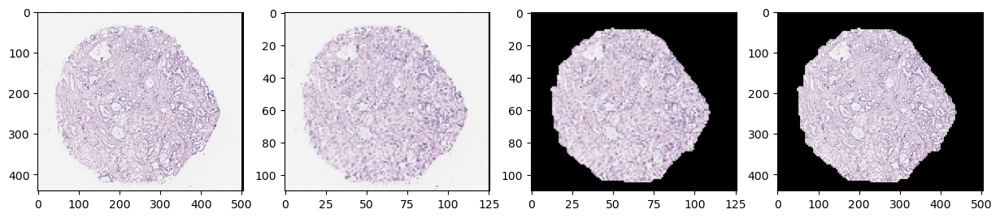

In [4]:
###################################
## GET TILE COORDINATES - CHECKS ##
###################################

## Compute pixel-tile tissue mask (For checks)
tile_map_masked = tile_map * mask
thumbnail_masked = thumbnail * cv2.resize(mask, (thumbnail.shape[1], thumbnail.shape[0]), cv2.INTER_LINEAR)[:,:,None] # (H, W)

## Visualise mask
fig, axes = plt.subplots(1, 4, figsize=(15, 5))
axes[0].imshow(thumbnail)
axes[1].imshow(tile_map)
axes[2].imshow(tile_map_masked)
axes[3].imshow(thumbnail_masked)
plt.show()
plt.close()

#
###

In [5]:
###############################
## EXTRACT PATCHES FOR MODEL ##
###############################

## Parameters
LEVEL = 0 # Downsampling level 
TILE_SIZE_MODEL = 1024 # Size of tile for model

## Adjust tile size based on downsampling
ds = 1
if LEVEL > 0: 
    ds = 4 * LEVEL
TILE_SIZE_MODEL = int(TILE_SIZE_MODEL/ds)

## Remove patches too close to the edges
tile_coordinates_ds = []
for tile_coordinates_ in tile_coordinates:
    coords_0_lo = tile_coordinates_[0] + int(TILE_SIZE/2) - int(TILE_SIZE_MODEL/2)
    coords_0_hi = tile_coordinates_[0] + int(TILE_SIZE/2) + int(TILE_SIZE_MODEL/2)
    coords_1_lo = tile_coordinates_[1] + int(TILE_SIZE/2) - int(TILE_SIZE_MODEL/2)
    coords_1_hi = tile_coordinates_[1] + int(TILE_SIZE/2) + int(TILE_SIZE_MODEL/2)
    if (coords_0_lo > 0) & (coords_0_hi < canvas_size[0]) & (coords_1_lo > 0) & (coords_1_hi < canvas_size[1]):
        tile_coordinates_ds += [[coords_0_lo, coords_1_lo]]

## Get patches closest to grid points
tile_coordinates_ds = select_patches_on_grid(tile_coordinates_ds, grid_spacing=512)
print(f'Number of patches: {len(tile_coordinates_ds)}')

## Load patches from the dataset
patches = slide_path_to_tiles_at_coordinates(WSI_PATH, tile_coordinates_ds, TILE_SIZE_MODEL, LEVEL) # [dataset[i] for i in range(min(num_patches_to_display, len(dataset)))]

#
###

Number of patches: 160


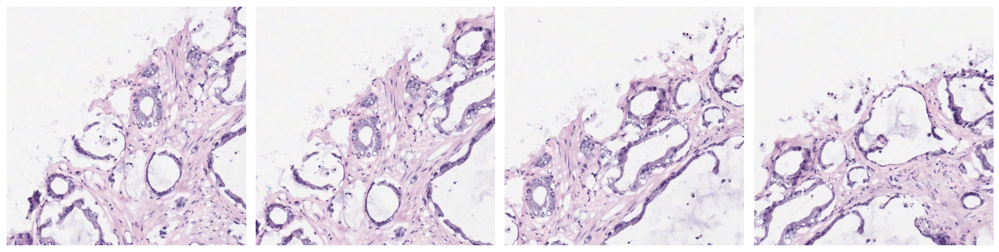

In [6]:
########################################
## EXTRACT PATCHES FOR MODEL - CHECKS ##
########################################

## Display the patches
num_patches_to_display = 4
fig, axes = plt.subplots(1, num_patches_to_display, figsize=(15, 5))
for i, ax in enumerate(axes.flat):
    if i < len(patches):
        ax.imshow(patches[i])
        ax.axis('off')
    else:
        ax.axis('off') # Hide unused subplots if any
plt.tight_layout()
plt.show()

#
###

In [7]:
####################
## REASSEMBLE WSI ##
####################

## Reassemble image
img = reassemble_tiles(patches, tile_coordinates_ds, canvas_size[0], canvas_size[1])

## Mask
img = img * tissue_mask

#
###

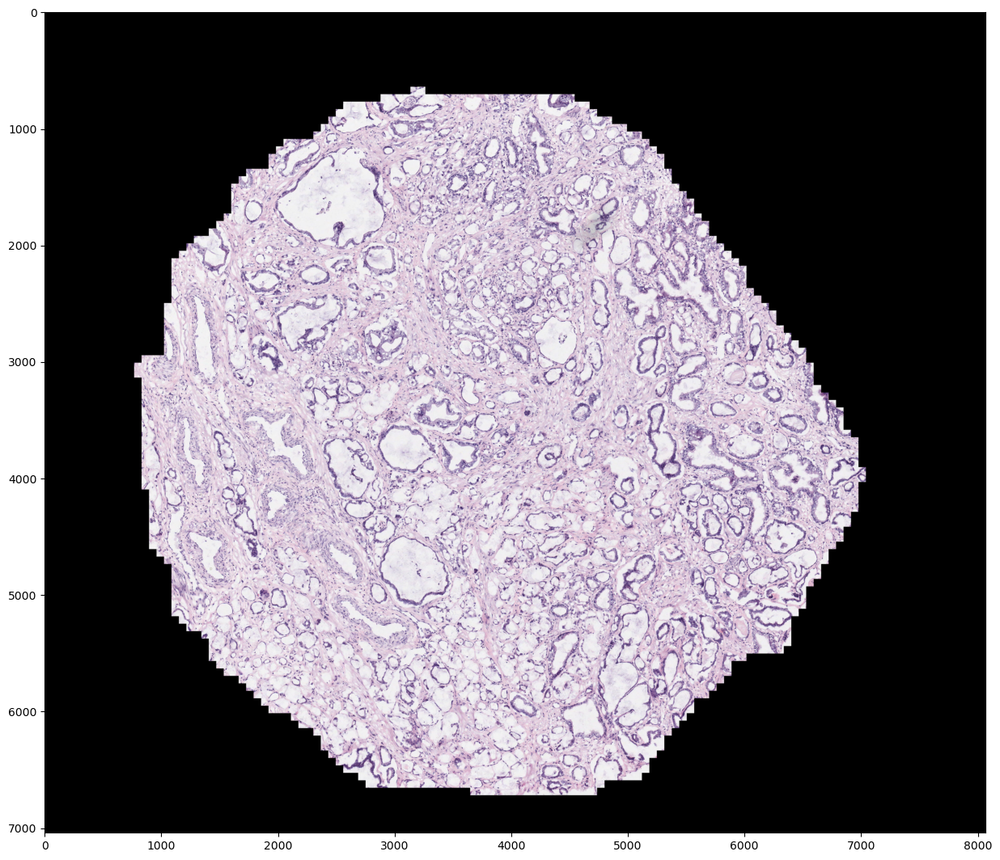

In [8]:
#############################
## REASSEMBLE WSI - CHECKS ##
#############################

## Visualise
fig, axes = plt.subplots(1, 1, figsize=(15, 15))
axes.imshow(img)
plt.show()
plt.close()

#
###

In [9]:
#####################################
## FUNCTIONS FOR MODEL APPLICATION ##
#####################################

## numpy_to_device
## Goal:
## Format numpy array for model.
## Inputs:
## X (list of numpy arrays): Input array for the model (B, H, W, C).
## Outputs:
## tensors (list of torch tensors): Output tensor for model (B, C, H, W).
def numpy_to_device(X, tile_size, device):
    tensors = []
    for x in X:        
        x = cv2.resize(x, (tile_size, tile_size))
        x = torch.tensor(x)        
        x = x.swapaxes(2, 1).swapaxes(1, 0) # (H, W, C) --> (C, H, W)
        x = x.float()
        x = x[None, :, :, :] # (C, H, W) --> (B=1, C, H, W)
        x = x.to(device)
        tensors += [x]        
    return tensors

## device_to_numpy
## Goal: 
## Format tensor on device back to numpy array.
## Inputs:
## X (list of torch tensors): List of torch tensors predictions from the model (B, C, H, W).
## Outputs:
## images (list of numpy arrays): List of images produced by the model after re-formatting (B, H, W, C).
def device_to_numpy(X, tile_size):
    images = []
    for x in X:
        x = torch.sigmoid(x) * 255 # Logits to probabilities to [0, 255]
        x = x.cpu().numpy()
        x = x.swapaxes(0, 1).swapaxes(1, 2)    
        x = x.astype('uint8')
        x = cv2.resize(x, (tile_size, tile_size))
        x = np.argmax(x, axis=2).reshape(x.shape[0], x.shape[1], 1) # Only for multiple classes
        images += [x]        
    return images

#
###

In [10]:
#################
## APPLY MODEL ##
#################

## Parameters
DEVICE = "mps" # Device to load model, tiles, and perform computations
# PT_MODEL_IN = 'models/r10_3.pth'
# NUM_CLASSES = 4 # Number of outputs given by model
PT_MODEL_IN = 'models/TransUNet_V2_0.pth' # Path to model weights
NUM_CLASSES = 3 # Number of outputs given by model

## Load model
print(f"Using {DEVICE} device")
model = Model(n_classes=NUM_CLASSES).to(DEVICE)
if os.path.exists(PT_MODEL_IN):
    model.load_state_dict(torch.load(PT_MODEL_IN))
    print("Loaded model")

## Apply to all tiles
preds = []
X = numpy_to_device(patches, TILE_SIZE_MODEL, DEVICE)
with torch.no_grad():
    for x in X:                
        preds_ = model(x)        
        preds_ = device_to_numpy(preds_, TILE_SIZE_MODEL)[0] # WiP: Only for single patch
        preds += [preds_] # WiP: Only for single patch

#
###

Using mps device
Loaded model


/Users/willembonnaffe/anaconda3/envs/pytorch/lib/python3.8/site-packages/torch/nn/functional.py:3959: UserWarning: MPS: passing scale factor to upsample ops is supported natively starting from macOS 13.0. Falling back on CPU. This may have performance implications. (Triggered internally at /Users/runner/work/_temp/anaconda/conda-bld/pytorch_1682343685278/work/aten/src/ATen/native/mps/operations/UpSample.mm:233.)
  return torch._C._nn.upsample_bilinear2d(input, output_size, align_corners, scale_factors)


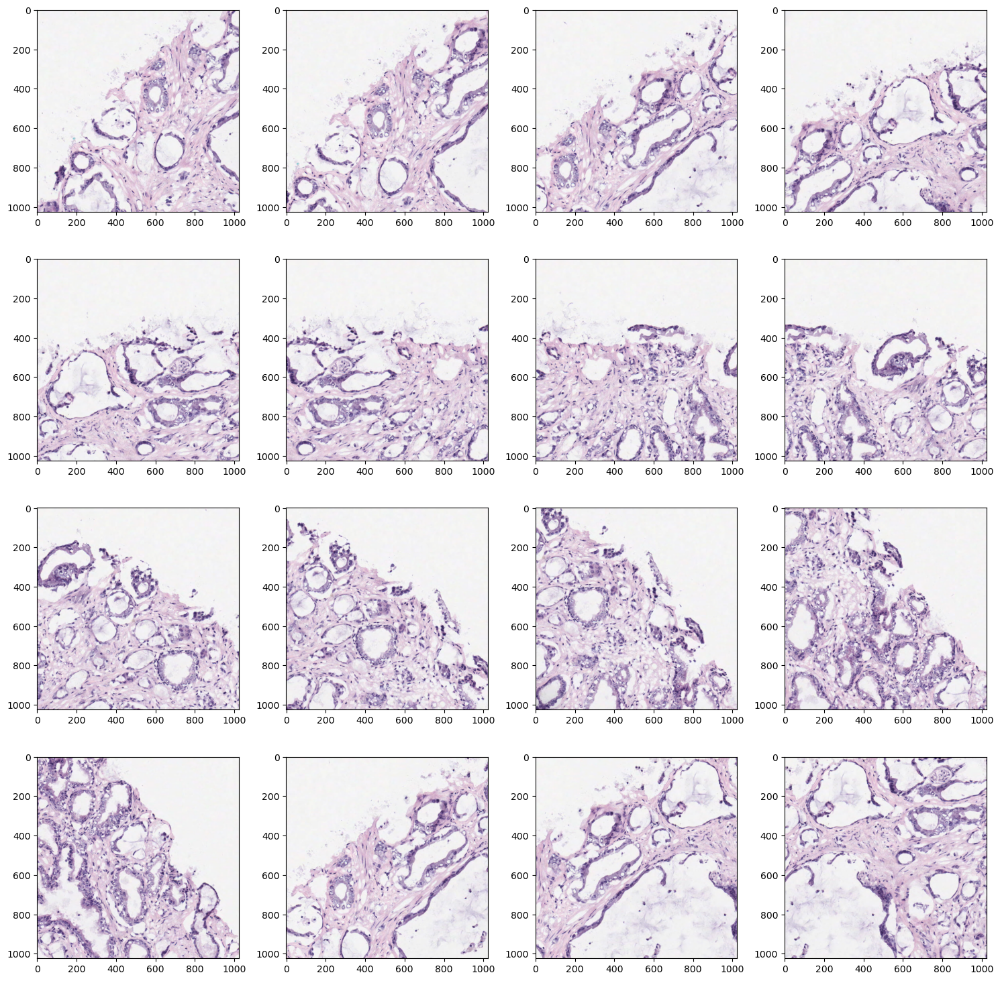

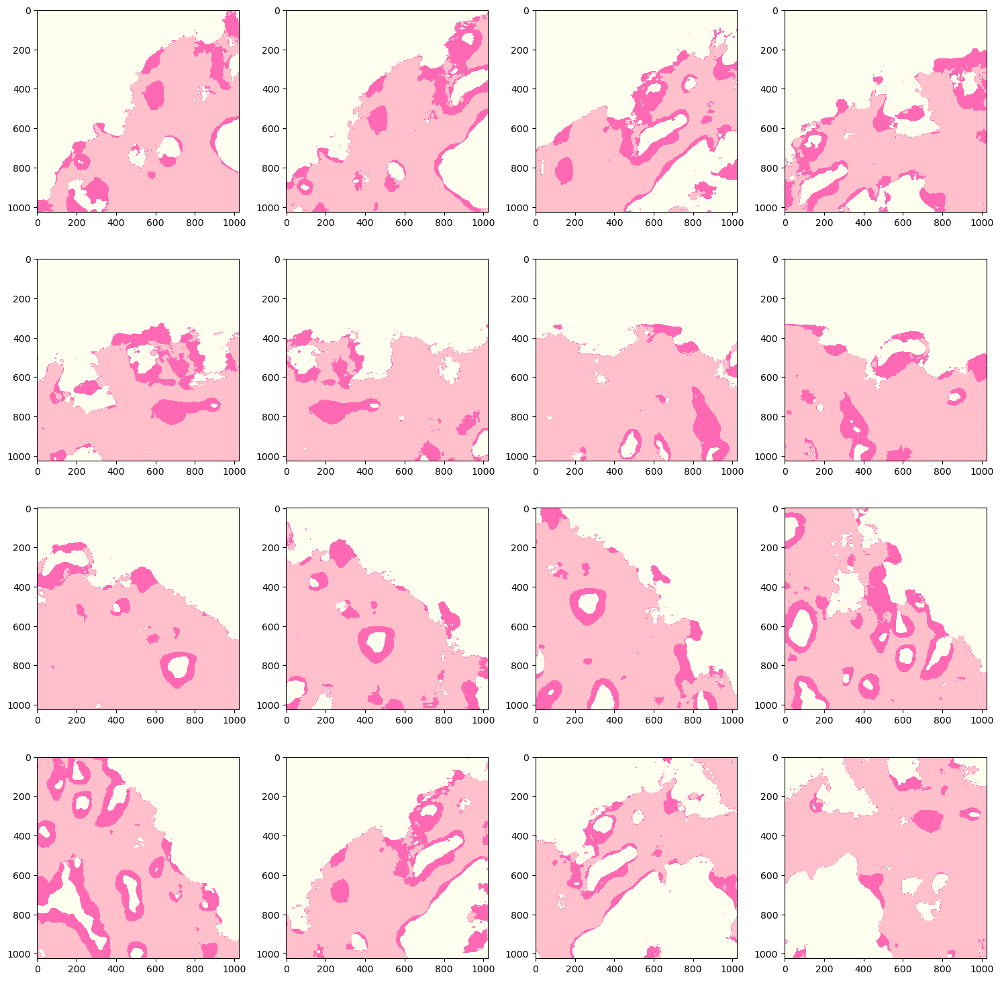

In [11]:
##########################
## APPLY MODEL - CHECKS ##
##########################

## Parameters
theme = 'H&E'

## Graphical parameters
if theme == 'H&E':
    from matplotlib.colors import ListedColormap
    custom_cmap = ListedColormap(['pink', 'hotpink', 'ivory'])
else:
    custom_cmap = 'gist_gray'

## Visualise image patches
fig, axes = plt.subplots(4, 4, figsize=(15,15))
k = 0
for i in range(4):
    for j in range(4):
        axis = axes[i,j]        
        axis.imshow(patches[k], cmap=custom_cmap)
        k += 1
plt.tight_layout()
plt.show()
plt.close()

## Visualise prediction patches
fig, axes = plt.subplots(4, 4, figsize=(15,15))
k = 0
for i in range(4):
    for j in range(4):
        axis = axes[i,j]
        axis.imshow(preds[k], cmap=custom_cmap)        
        k += 1
plt.tight_layout()
plt.show()
plt.close()

#
###

In [12]:
############################
## REASSEMBLE PREDICTIONS ##
############################

## Assemble predictions
mask = reassemble_tiles(preds, tile_coordinates_ds, canvas_size[0], canvas_size[1])
mask = mask[:,:,0].reshape(mask.shape[0], mask.shape[1], 1) * tissue_mask

#
###

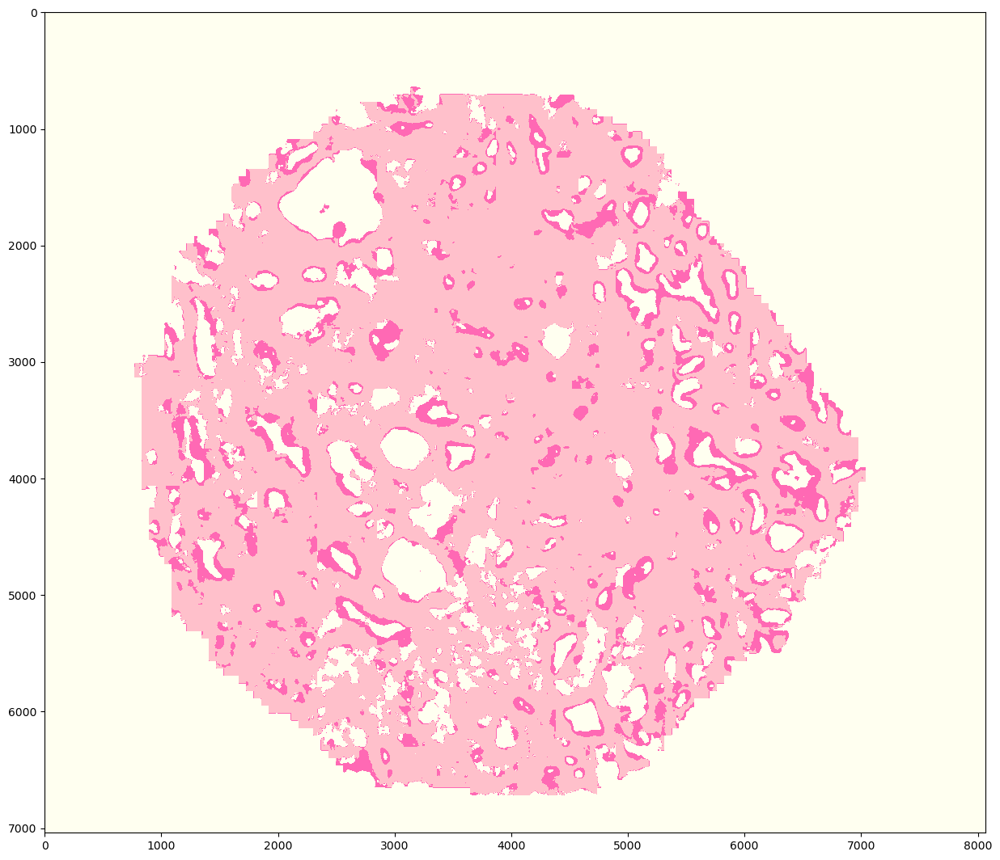

In [13]:
#####################################
## REASSEMBLE PREDICTIONS - CHECKS ##
#####################################

## Visualise
fig, axes = plt.subplots(1, 1, figsize=(15, 15))
if theme == 'H&E':
    axes.imshow(mask + (1 - tissue_mask) * 2, cmap=custom_cmap)
else:
    axes.imshow(mask, cmap=custom_cmap)
plt.show()
plt.close()

#
###

In [14]:
########################################
## PREPARE MASK FOR OBJECT EXTRACTION ##
########################################

## Parameters
DOWNSAMPLE_EXTRACTION = 4 # Downsample factor of mask for extraction of objects
NUM_POLISH = 1 # Number of times to erode mask (reduced clumped objects but may lose small objects)

## Binarise mask
mask = ((mask > 0)*1).astype('uint8')
mask = cv2.resize(mask, (int(mask.shape[1]/DOWNSAMPLE_EXTRACTION), int(mask.shape[0]/DOWNSAMPLE_EXTRACTION)))
mask = mask[:,:,None]

## Polish mask
for i in range(NUM_POLISH):
    mask = polish(mask)

#
###

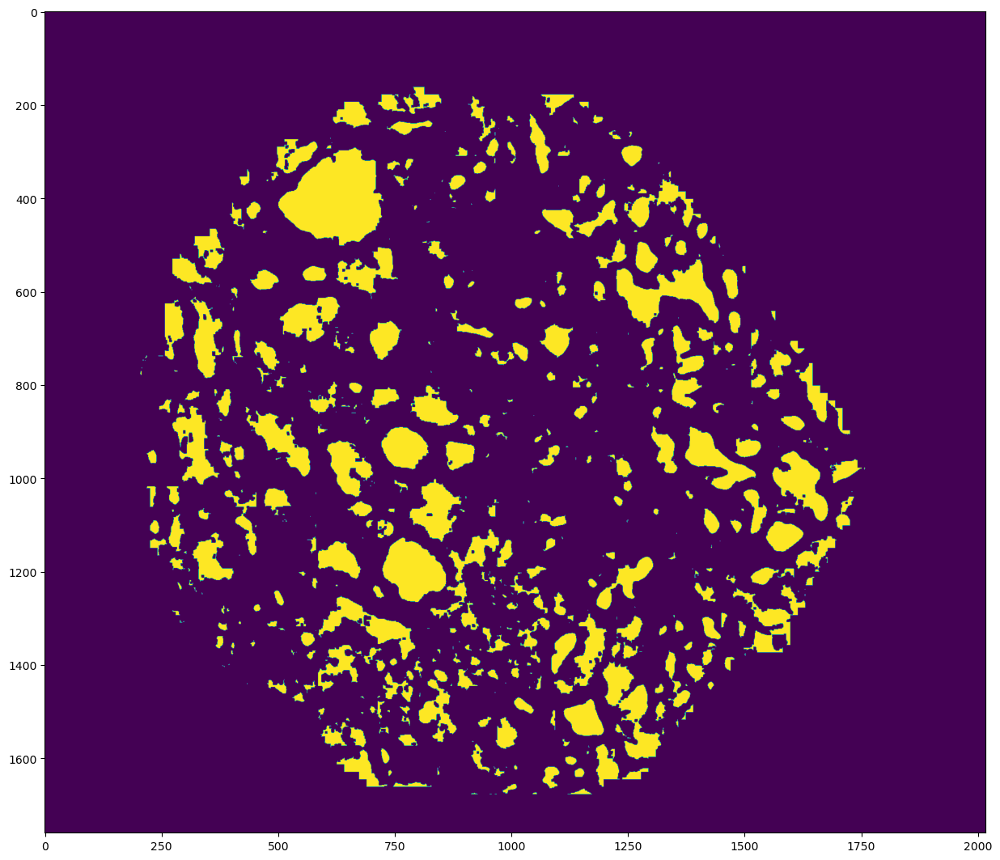

In [15]:
#################################################
## PREPARE MASK FOR OBJECT EXTRACTION - CHECKS ##
#################################################

## Visualise
fig, axes = plt.subplots(1, 1, figsize=(15,15))
axes.imshow(mask)
plt.show()
plt.close()

#
###

In [16]:
#####################
## EXTRACT OBJECTS ##
#####################

## Get objects
gland_coords = extract_object_pixels(mask)
print(f'Number of glands: {len(gland_coords)}')

## Rescale coordinates to original size
rescaled_gland_coords = [coords * DOWNSAMPLE_EXTRACTION for coords in gland_coords]

#
###

Number of glands: 552


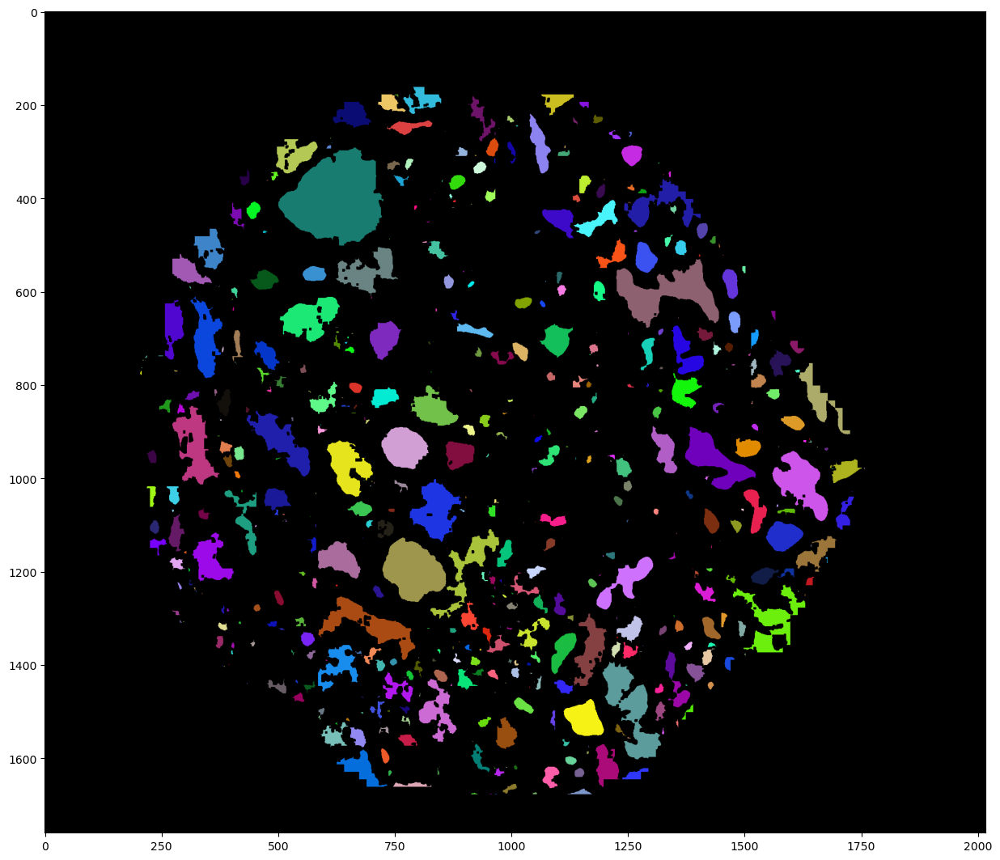

In [17]:
##############################
## EXTRACT OBJECTS - CHECKS ##
##############################

## Visualise objects
fig, axes = plt.subplots(1, 1, figsize=(15,15))
axes.imshow(inlay_objects(mask, gland_coords))
plt.show()
plt.close()

#
###

In [18]:
##################
## SAVE OBJECTS ##
##################

## Parameters
BUFFER = 30 # Added distance around bounding box (in pixels)
THRESHOLD_MIN = 100 # Minimum surface area of objects (in pixels)
THRESHOLD_MAX = 2000 * 100 # Maximum surface area of objects (in pixels)
PROP_BLACK = 0.01 # Maximum proportion of border pixels in image (proportion)
PT_OUTPUT_FOLDER = '/Users/willembonnaffe/Desktop/extracted_objects_15' # Path where the gland images should be saved

## Paths
os.makedirs(PT_OUTPUT_FOLDER, exist_ok=True)

## Extract and save each object
objects = []
for i, coords in enumerate(rescaled_gland_coords):

    ## Discard small objects
    if (len(coords) > THRESHOLD_MIN) & (len(coords) < THRESHOLD_MAX):
        
        ## Get bounding box of the object
        x_min, y_min, x_max, y_max = get_bounding_box_square(coords)
    
        ## Get object
        object_img = img[(x_min - BUFFER):(x_max + BUFFER), (y_min - BUFFER):(y_max + BUFFER)]

        ## Check size
        if (object_img.shape[0] > 0) & (object_img.shape[1] > 0):

            ## Check colour
            object_img = cv2.cvtColor(object_img, cv2.COLOR_BGR2RGB)    
            if (object_img.mean(2) < 10).sum()/(object_img.shape[0] * object_img.shape[1]) < PROP_BLACK:    
        
                ## Save the object image
                objects += [object_img]
                object_filename = os.path.join(PT_OUTPUT_FOLDER, f'{os.path.basename(WSI_PATH)}_object_{i}.png')
                cv2.imwrite(object_filename, object_img)

#
###

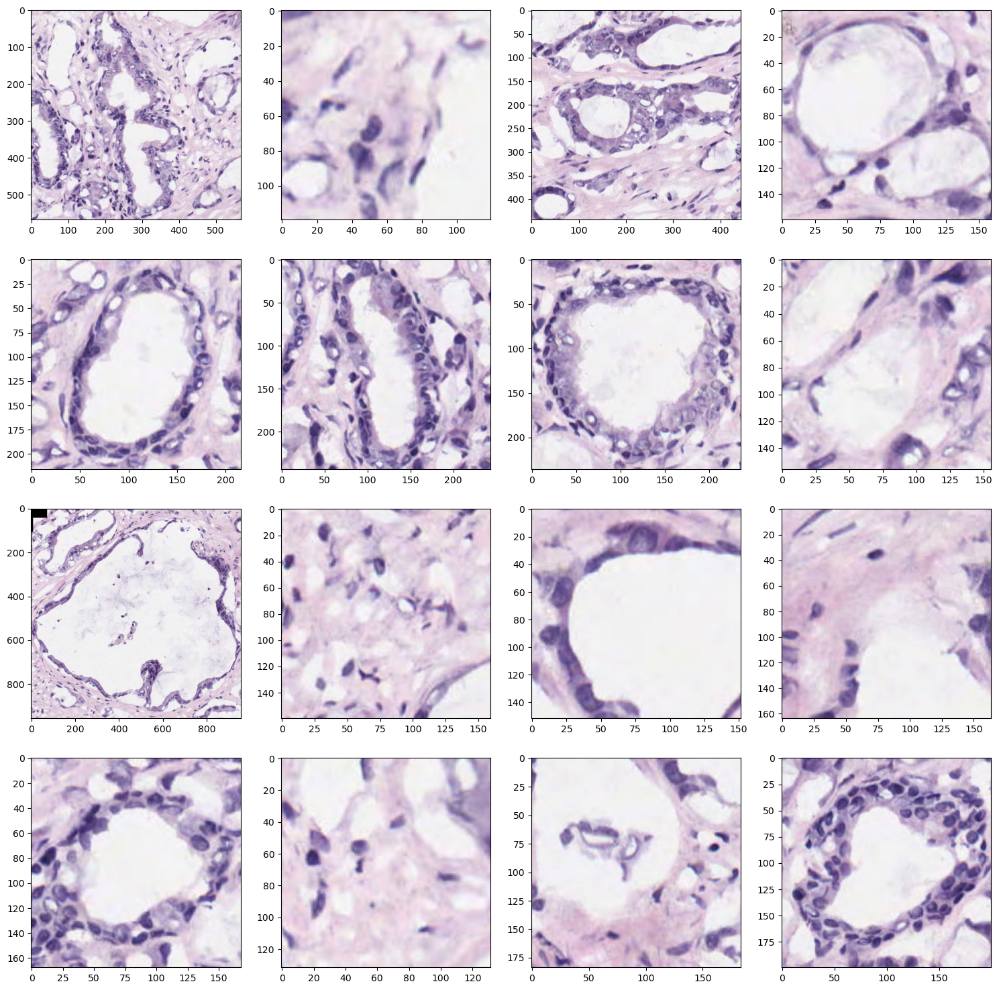

In [19]:
###########################
## SAVE OBJECTS - CHECKS ##
###########################

## Visualise image patches
fig, axes = plt.subplots(4, 4, figsize=(15,15))
k = 0
for i in range(4):
    for j in range(4):
        axis = axes[i,j]        
        axis.imshow(cv2.cvtColor(objects[k], cv2.COLOR_BGR2RGB))
        k += 1
plt.tight_layout()
plt.show()
plt.close()

#
###